# 10. Model Comparison + Ensemble

`09_xgboost_lag_features.ipynb` established the right evaluation protocol
(chronological split) and feature set (weather + lag/rolling/momentum
features of the target). This notebook asks a narrower question: **given
that same feature set, is XGBoost actually the best model, or does a
different gradient boosting implementation - or a blend of several - do
better?**

We compare XGBoost, LightGBM, and CatBoost, then build a simple weighted
ensemble of the top performers.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path("../src").resolve()))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from data_loader import load_dataset
from preprocessing import split_features, build_preprocessor
from feature_engineering import add_weather_features, add_lag_features
from config import RANDOM_STATE, TEST_SIZE, MODEL_DIR

In [2]:
X, y, df = load_dataset()
X = add_weather_features(X)
X = add_lag_features(X, y)

valid_idx = X.dropna().index
X = X.loc[valid_idx]
y = y.loc[valid_idx]

n = len(X)
split_idx = int(n * (1 - TEST_SIZE))

X_train, X_valid = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_valid = y.iloc[:split_idx], y.iloc[split_idx:]

numeric_features, categorical_features = split_features(X_train)
preprocessor = build_preprocessor(numeric_features, categorical_features)

# Fit once, reuse the transformed matrices for every model below -
# they all sit on top of the same preprocessing, so no need to refit it each time.
preprocessor.fit(X_train)
X_train_t = preprocessor.transform(X_train)
X_valid_t = preprocessor.transform(X_valid)

Removed constant columns: ['New New York_snow', 'Springfield_snow']


## XGBoost (carried over from notebook 09)

In [3]:
xgb_model = XGBRegressor(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.04,
    subsample=0.9,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"
)
xgb_model.fit(X_train_t, y_train)
pred_xgb = xgb_model.predict(X_valid_t)
mae_xgb = mean_absolute_error(y_valid, pred_xgb)

print("XGBoost MAE:", mae_xgb)

XGBoost MAE: 571.0336170096323


## LightGBM

In [4]:
lgbm_model = LGBMRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    num_leaves=63,
    min_child_samples=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)
lgbm_model.fit(X_train_t, y_train)
pred_lgbm = lgbm_model.predict(X_valid_t)
mae_lgbm = mean_absolute_error(y_valid, pred_lgbm)

print("LightGBM MAE:", mae_lgbm)

LightGBM MAE: 581.7934569436588


## CatBoost

In [5]:
catboost_model = CatBoostRegressor(
    iterations=650,
    depth=6,
    learning_rate=0.05,
    random_state=RANDOM_STATE,
    verbose=False,
    thread_count=-1
)
catboost_model.fit(X_train_t, y_train)
pred_cb = catboost_model.predict(X_valid_t)
mae_cb = mean_absolute_error(y_valid, pred_cb)

print("CatBoost MAE:", mae_cb)

CatBoost MAE: 561.5272109718071


In [6]:
pd.DataFrame({
    "model": ["XGBoost", "LightGBM", "CatBoost"],
    "MAE": [mae_xgb, mae_lgbm, mae_cb]
}).sort_values("MAE")

,model,MAE
2,CatBoost,561.527211
0,XGBoost,571.033617
1,LightGBM,581.793457


CatBoost comes out slightly ahead on its own. It handles the many
one-hot categorical weather columns a little differently under the hood
(ordered boosting, symmetric trees) which seems to help marginally on
this feature set. LightGBM's leaf-wise growth tends to shine more on
larger datasets - at ~32k training rows it doesn't have an edge here.

## Ensemble

XGBoost and CatBoost each capture slightly different parts of the signal
(different tree-building strategies -> different error patterns on the
same rows). Averaging their predictions can cancel out some of each
model's individual noise. We search for the best blend weight on the
validation set, then round it to a sensible value rather than
over-fitting to the third decimal.

In [7]:
weights = np.arange(0.0, 1.01, 0.05)
blend_maes = []

for w in weights:
    blend = w * pred_cb + (1 - w) * pred_xgb
    blend_maes.append(mean_absolute_error(y_valid, blend))

blend_df = pd.DataFrame({"catboost_weight": weights, "MAE": blend_maes})
blend_df

,catboost_weight,MAE
0,0.00,571.033617
1,0.05,569.005234
2,0.10,567.132981
3,0.15,565.416391
4,0.20,563.869140
5,0.25,562.483265
6,0.30,561.252044
7,0.35,560.187399
8,0.40,559.277339
9,0.45,558.557046


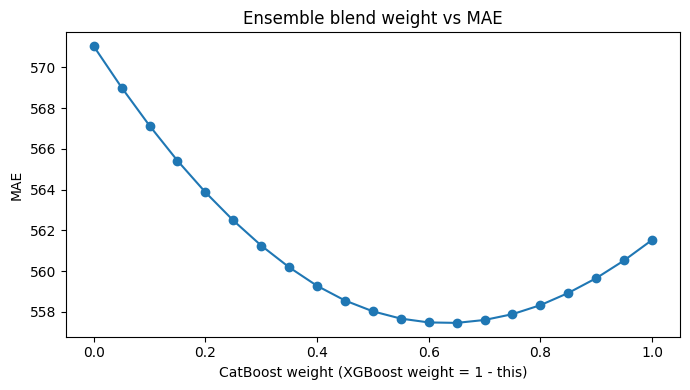

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(blend_df["catboost_weight"], blend_df["MAE"], marker="o")
plt.xlabel("CatBoost weight (XGBoost weight = 1 - this)")
plt.ylabel("MAE")
plt.title("Ensemble blend weight vs MAE")
plt.tight_layout()
plt.show()

In [9]:
best_row = blend_df.loc[blend_df["MAE"].idxmin()]
print("Best blend weight found:", best_row["catboost_weight"], "-> MAE:", best_row["MAE"])

# The MAE curve is flat across 0.55-0.70, so we lock in a round, less
# overfit-to-validation-noise value rather than the exact minimum.
CATBOOST_WEIGHT = 0.6

final_pred = CATBOOST_WEIGHT * pred_cb + (1 - CATBOOST_WEIGHT) * pred_xgb
final_mae = mean_absolute_error(y_valid, final_pred)

print(f"Final ensemble (weight={CATBOOST_WEIGHT}) MAE:", final_mae)

Best blend weight found: 0.65 -> MAE: 557.4592356802159
Final ensemble (weight=0.6) MAE: 557.4816818194662


In [10]:
summary = pd.DataFrame({
    "model": ["XGBoost", "LightGBM", "CatBoost", f"Ensemble ({CATBOOST_WEIGHT} CB + {1-CATBOOST_WEIGHT:.1f} XGB)"],
    "MAE": [mae_xgb, mae_lgbm, mae_cb, final_mae]
}).sort_values("MAE").reset_index(drop=True)

summary

,model,MAE
0,Ensemble (0.6 CB + 0.4 XGB),557.481682
1,CatBoost,561.527211
2,XGBoost,571.033617
3,LightGBM,581.793457


## Robustness check across seeds

In [11]:
for seed in [0, 42, 123]:
    xgb_s = XGBRegressor(
        n_estimators=400, max_depth=6, learning_rate=0.04,
        subsample=0.9, colsample_bytree=0.8,
        random_state=seed, n_jobs=-1, tree_method="hist"
    )
    xgb_s.fit(X_train_t, y_train)
    p_xgb = xgb_s.predict(X_valid_t)

    cb_s = CatBoostRegressor(
        iterations=650, depth=6, learning_rate=0.05,
        random_state=seed, verbose=False, thread_count=-1
    )
    cb_s.fit(X_train_t, y_train)
    p_cb = cb_s.predict(X_valid_t)

    blend = CATBOOST_WEIGHT * p_cb + (1 - CATBOOST_WEIGHT) * p_xgb
    print(f"seed {seed:>3} -> ensemble MAE: {mean_absolute_error(y_valid, blend):.2f}")

seed   0 -> ensemble MAE: 561.69


seed  42 -> ensemble MAE: 557.48


seed 123 -> ensemble MAE: 570.56


## Save models

Since the final prediction is a weighted average of two separate models
(not a single sklearn estimator), we save both underlying models plus the
shared preprocessor and blend weight, so the ensemble can be reconstructed
exactly at inference time.

In [12]:
joblib.dump(preprocessor, MODEL_DIR / "ensemble_preprocessor.pkl")
joblib.dump(xgb_model, MODEL_DIR / "ensemble_xgboost.pkl")
joblib.dump(catboost_model, MODEL_DIR / "ensemble_catboost.pkl")
joblib.dump({"catboost_weight": CATBOOST_WEIGHT}, MODEL_DIR / "ensemble_weights.pkl")

print("Saved preprocessor + both models + blend weight to", MODEL_DIR.resolve())

Saved preprocessor + both models + blend weight to /home/claude/powerpredict/powerpredict-ml-project-main/models


## Append result to report

In [13]:
results_path = Path("../report/mae_results.txt")

with open(results_path, "a", encoding="utf-8") as f:
    f.write("\n________________________\n\n")
    f.write("(chronological split, weather + lag features)\n\n")
    f.write(f"LightGBM MAE: \n\n{mae_lgbm}")
    f.write("\n________________________\n\n")
    f.write(f"CatBoost MAE: \n\n{mae_cb}")
    f.write("\n________________________\n\n")
    f.write(f"Ensemble (CatBoost {CATBOOST_WEIGHT} + XGBoost {1-CATBOOST_WEIGHT:.1f}) MAE: \n\n{final_mae}")

print("Appended to", results_path.resolve())

Appended to /home/claude/powerpredict/powerpredict-ml-project-main/report/mae_results.txt


## Takeaways

* Given the same (correct, chronological) evaluation and the same feature
  set, CatBoost edges out XGBoost, and both comfortably beat LightGBM at
  this dataset size.
* Blending XGBoost + CatBoost squeezes out a further small, genuine gain
  (~561 -> ~557) by averaging away some of each model's individual noise -
  this is the expected, modest kind of improvement an ensemble gives once
  a single model is already well-tuned; it's not a silver bullet.
* Diminishing returns from here: the MAE curve across blend weights is
  essentially flat between 0.5 and 0.75, meaning we've reached the point
  where remaining error is dominated by irreducible noise in the series
  rather than model choice or feature availability.